# Historical source sanity — v2

Execute in the persistent `fraud-ml-prod/historical-sanity` Kubeflow Notebook. Credentials come from `historical-source`; no credential values are displayed. The accepted dataset is the finite prod Argo Workflow output, not a locally generated substitute.

This source-level learnability experiment uses simulation truth for evaluation. It is not the governed, delayed-label training baseline in #53. Predictors contain checkout/attempt facts and strictly earlier history; no scenario, truth, risk decision or future outcome is a feature.


In [1]:
import subprocess
import sys

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "--quiet",
        "duckdb==1.5.6",
        "pyarrow==24.0.0",
        "boto3==1.43.116",
        "scikit-learn==1.8.0",
        "pandas==3.0.6",
    ],
    check=True,
)

CompletedProcess(args=['/opt/conda/bin/python', '-m', 'pip', 'install', '--quiet', 'duckdb==1.5.6', 'pyarrow==24.0.0', 'boto3==1.43.116', 'scikit-learn==1.8.0', 'pandas==3.0.6'], returncode=0)

In [2]:
import hashlib
import importlib.metadata
import json
import os
from pathlib import Path

import boto3
import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.fs as fs
import pyarrow.parquet as pq
from botocore.exceptions import ClientError
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

version = "v2"
endpoint = "minio.home.phuchoang.sbs"
source = fs.S3FileSystem(
    access_key=os.environ["AWS_ACCESS_KEY_ID"],
    secret_key=os.environ["AWS_SECRET_ACCESS_KEY"],
    region="us-east-1",
    scheme="https",
    endpoint_override=endpoint,
    force_virtual_addressing=False,
)
prefix = f"synthetic-source/historical/{version}"
with source.open_input_file(f"{prefix}/manifest.json") as stream:
    manifest_bytes = stream.read()
manifest = json.loads(manifest_bytes)
manifest_sha256 = hashlib.sha256(manifest_bytes).hexdigest()
assert manifest["dataset_version"] == version
cache = Path("source-cache") / version
cache.mkdir(parents=True, exist_ok=True)
fs.copy_files(
    prefix,
    str(cache.resolve()),
    source_filesystem=source,
    destination_filesystem=fs.LocalFileSystem(),
    use_threads=False,
)
report = json.loads((cache / manifest["validation_report"]).read_text())
assert all(check["result"] in ("passed", "info") for check in report["checks"])
provenance = {
    "dataset_version": version,
    "manifest_sha256": manifest_sha256,
    "seed": manifest["seed"],
    "generator_revision": manifest["generator_revision"],
    "contract": manifest["contract"],
    "history_end": manifest["history_end"],
    "native_checks": len(report["checks"]),
    "versions": {
        name: importlib.metadata.version(name)
        for name in ("duckdb", "pyarrow", "pandas", "scikit-learn", "matplotlib")
    },
}
display(provenance)

{'dataset_version': 'v2',
 'manifest_sha256': '5b45cbbafcc06b8e1cea23ff968cde8a219f9baa534afbedf7c9a0cae2b8cd3d',
 'seed': 2603,
 'generator_revision': '589671132dc5cbd8c4cb6ac502c1afdd0572b630362adfd895e859dc4f3aa896',
 'contract': {'id': 'urn:datacontract:fraud:historical-payments',
  'sha256': '02574f2536ba42a4524ec6b992ced6b78c9817e4efb860228b1da626c0f518e4',
  'version': '1.0.0'},
 'history_end': '2026-10-21T00:38:00+00:00',
 'native_checks': 233,
 'versions': {'duckdb': '1.5.6',
  'pyarrow': '24.0.0',
  'pandas': '3.0.6',
  'scikit-learn': '1.8.0',
  'matplotlib': '3.10.9'}}

## Storage, quality and physical cutover

Count physical rows before deduplication, compare each date partition with the manifest, inspect nested Arrow layouts, and measure duplicate content independently. Labels are partitioned by availability time. Complete histories span event partitions.


In [3]:
con = duckdb.connect(config={"threads": 2, "memory_limit": "1GiB"})
for name in ("payment_events", "fraud_labels"):
    paths = sorted((cache / name).rglob("*.parquet"))
    con.read_parquet([str(p) for p in paths], union_by_name=True, hive_partitioning=False).create_view(name)
    partition_name = "occurred_date" if name == "payment_events" else "label_available_date"
    actual = {}
    for partition in sorted((cache / name).glob(f"{partition_name}=*")):
        actual[partition.name.split("=", 1)[1]] = sum(
            pq.ParquetFile(p).metadata.num_rows for p in partition.glob("*.parquet")
        )
    assert actual == manifest["partitions"][name]
cutover = manifest["configured"]["schema_cutover"]
physical = []
for path in sorted((cache / "payment_events").rglob("*.parquet")):
    file = pq.ParquetFile(path)
    day = path.parent.name.split("=", 1)[1]
    signals = file.schema_arrow.field("attempt_started").type.field("signals").type
    present = "user_agent_family" in [field.name for field in signals]
    assert present == (day >= cutover)
    physical.append(
        {
            "date": day,
            "user_agent_column": present,
            "rows": file.metadata.num_rows,
            "row_groups": file.metadata.num_row_groups,
            "codec": file.metadata.row_group(0).column(0).compression,
        }
    )
duplicates = con.sql("SELECT count(*) - count(DISTINCT event_id) FROM payment_events").fetchone()[0]
row_count = con.sql("SELECT count(*) FROM payment_events").fetchone()[0]
assert duplicates == manifest["observed"]["duplicate_events"]
conflicts = con.sql(
    "SELECT count(*) FROM (SELECT event_id FROM payment_events e GROUP BY event_id HAVING count(DISTINCT to_json(e)) > 1)"
).fetchone()[0]
assert conflicts == 0
cutover_nulls = con.sql("""SELECT CAST(occurred_at AS DATE) AS day,
  count(*) AS attempts,
  count(attempt_started.signals.user_agent_family) AS user_agent_values
FROM payment_events WHERE attempt_started IS NOT NULL GROUP BY day ORDER BY day""").df()
assert all(
    (row.user_agent_values == 0 if str(row.day.date()) < cutover else row.user_agent_values == row.attempts)
    for row in cutover_nulls.itertuples()
)
display(cutover_nulls)
display(pd.DataFrame(physical))
display(
    {
        "physical_events": row_count,
        "duplicate_rows": duplicates,
        "duplicate_rate": duplicates / row_count,
        "storage": manifest["storage"],
    }
)

,day,attempts,user_agent_values
0,2026-10-12,1570,0
1,2026-10-13,1554,0
2,2026-10-14,1544,0
3,2026-10-15,1554,0
4,2026-10-16,1515,1515
5,2026-10-17,1579,1579
6,2026-10-18,1579,1579
7,2026-10-19,1620,1620
8,2026-10-20,1525,1525


,date,user_agent_column,rows,row_groups,codec
0,2026-10-12,False,7980,1,ZSTD
1,2026-10-13,False,7844,1,ZSTD
2,2026-10-14,False,7806,1,ZSTD
3,2026-10-15,False,7852,1,ZSTD
4,2026-10-16,True,7671,1,ZSTD
5,2026-10-17,True,7978,1,ZSTD
6,2026-10-18,True,7943,1,ZSTD
7,2026-10-19,True,8198,1,ZSTD
8,2026-10-20,True,7717,1,ZSTD
9,2026-10-21,True,18,1,ZSTD


{'physical_events': 71007,
 'duplicate_rows': 1420,
 'duplicate_rate': 0.019998028363400793,
 'storage': {'compression': 'zstd',
  'compression_level': 3,
  'dictionary_encoding': True,
  'format': 'parquet',
  'fraud_labels': {'file_count': 30,
   'row_group_count': 30,
   'size_bytes': 814853,
   'sort_columns': ['label_available_at',
    'payment_id',
    'attempt_id',
    'source']},
  'payment_events': {'file_count': 10,
   'row_group_count': 10,
   'size_bytes': 8816742,
   'sort_columns': ['occurred_at',
    'payment_id',
    'aggregate_version',
    'event_id']},
  'write_statistics': True}}

,scenario,attempts,fraud_rate
0,legitimate,12651,0.0
1,retry_attack,256,1.0
2,stolen_card_new_device,213,1.0
3,compromised_device_farm,138,1.0
4,card_testing,137,1.0
5,account_takeover,128,1.0
6,reshipping_mule,99,1.0
7,obvious_high_value,76,1.0
8,friendly_fraud,71,0.0


,devices,networks,addresses,methods
0,4254,1516,3842,3047


,source,labels,min_delay_days,max_delay_days
0,LABEL_SOURCE_SIMULATION_TRUTH,13769,0,1
1,LABEL_SOURCE_CHARGEBACK,791,7,21


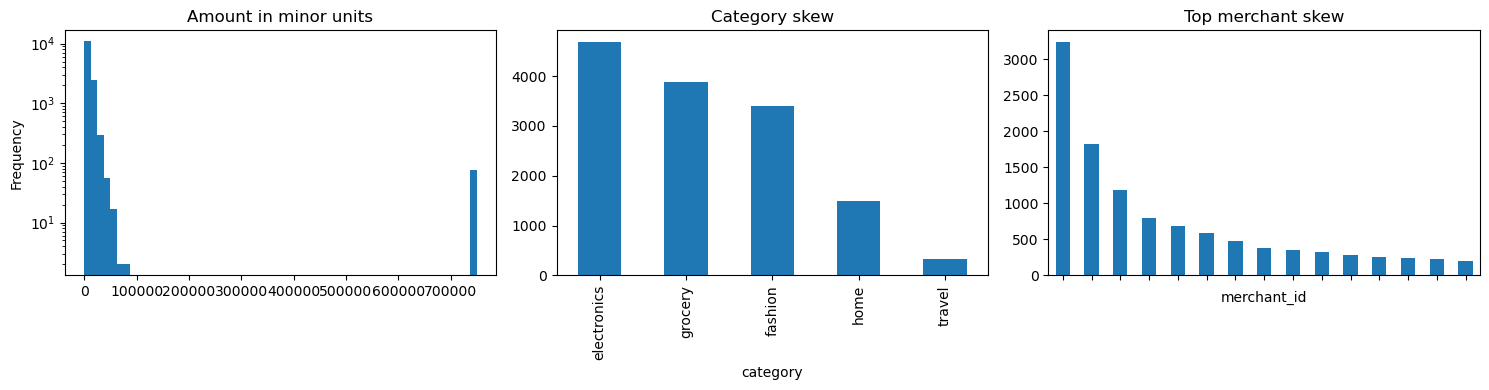

In [4]:
con.sql("CREATE VIEW canonical AS SELECT DISTINCT * FROM payment_events")
con.sql("""CREATE VIEW attempts AS
SELECT e.integration_id,e.payment_id,e.attempt_started.attempt_id AS attempt_id,
  e.occurred_at AS attempted_at,
  c.payment_created.customer.customer_id AS customer_id,
  c.payment_created.merchant.merchant_id AS merchant_id,
  c.payment_created.snapshot.total.minor_units AS amount,
  c.payment_created.snapshot.merchant_category AS category,
  date_diff('day',c.payment_created.snapshot.customer_account_created_at,e.occurred_at) AS account_age_days,
  CAST(e.attempt_started.signals.ip_country <> c.payment_created.snapshot.shipping.country AS INTEGER) AS foreign_ip,
  CAST(c.payment_created.snapshot.shipping.postal_code = '33166' AS INTEGER) AS forwarder,
  e.attempt_started.signals.device_fingerprint AS device,
  e.attempt_started.signals.ip_network_fingerprint AS network,
  e.attempt_started.signals.payment_method.fingerprint AS method,
  c.payment_created.snapshot.shipping.address_fingerprint AS address,
  t.is_fraud,t.scenario
FROM canonical e JOIN canonical c USING(integration_id,payment_id)
JOIN fraud_labels t ON t.integration_id=e.integration_id AND t.payment_id=e.payment_id
  AND t.attempt_id=e.attempt_started.attempt_id AND t.source='LABEL_SOURCE_SIMULATION_TRUTH'
WHERE e.attempt_started IS NOT NULL AND c.payment_created IS NOT NULL""")
summary = con.sql(
    "SELECT scenario,count(*) AS attempts,avg(CAST(is_fraud AS DOUBLE)) AS fraud_rate FROM attempts GROUP BY scenario ORDER BY attempts DESC"
).df()
distincts = con.sql(
    "SELECT approx_count_distinct(device) devices,approx_count_distinct(network) networks,approx_count_distinct(address) addresses,approx_count_distinct(method) methods FROM attempts"
).df()
merchant_skew = con.sql(
    "SELECT merchant_id,count(*) AS attempts FROM attempts GROUP BY merchant_id ORDER BY attempts DESC"
).df()
label_delays = con.sql(
    "SELECT source,count(*) AS labels,min(date_diff('day',occurred_at,label_available_at)) AS min_delay_days,max(date_diff('day',occurred_at,label_available_at)) AS max_delay_days FROM fraud_labels GROUP BY source"
).df()
display(summary)
display(distincts)
display(label_delays)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
con.sql("SELECT amount FROM attempts").df()["amount"].plot.hist(
    bins=60, logy=True, ax=axes[0], title="Amount in minor units"
)
con.sql("SELECT category,count(*) AS attempts FROM attempts GROUP BY category ORDER BY attempts DESC").df().plot.bar(
    x="category", y="attempts", ax=axes[1], legend=False, title="Category skew"
)
merchant_skew.head(15).plot.bar(x="merchant_id", y="attempts", ax=axes[2], legend=False, title="Top merchant skew")
axes[2].set_xticklabels([])
plt.tight_layout()
plt.show()

## Learnability from facts versus earlier history

Train on the first six occurrence dates and evaluate on later dates. Compute history using only timestamps strictly before each attempt. Both models have the same settings and exclude raw identifiers. Simulation truth is used solely as the target; this diagnostic does not claim production model accuracy or delayed-label availability at the split.


In [5]:
frame = con.sql("""SELECT *,
  count(*) OVER (PARTITION BY customer_id ORDER BY attempted_at RANGE BETWEEN INTERVAL 30 DAYS PRECEDING AND INTERVAL 1 MICROSECOND PRECEDING) AS customer_prior_attempts,
  avg(amount) OVER (PARTITION BY customer_id ORDER BY attempted_at RANGE BETWEEN INTERVAL 30 DAYS PRECEDING AND INTERVAL 1 MICROSECOND PRECEDING) AS customer_prior_amount,
  count(DISTINCT customer_id) OVER (PARTITION BY device ORDER BY attempted_at RANGE BETWEEN INTERVAL 1 DAY PRECEDING AND INTERVAL 1 MICROSECOND PRECEDING) AS device_prior_customers,
  count(DISTINCT method) OVER (PARTITION BY device ORDER BY attempted_at RANGE BETWEEN INTERVAL 1 HOUR PRECEDING AND INTERVAL 1 MICROSECOND PRECEDING) AS device_prior_methods,
  count(DISTINCT customer_id) OVER (PARTITION BY address ORDER BY attempted_at RANGE BETWEEN INTERVAL 1 DAY PRECEDING AND INTERVAL 1 MICROSECOND PRECEDING) AS address_prior_customers,
  count(*) OVER (PARTITION BY payment_id ORDER BY attempted_at RANGE BETWEEN UNBOUNDED PRECEDING AND INTERVAL 1 MICROSECOND PRECEDING) AS payment_prior_attempts,
  count(*) OVER (PARTITION BY customer_id,device ORDER BY attempted_at RANGE BETWEEN UNBOUNDED PRECEDING AND INTERVAL 1 MICROSECOND PRECEDING) AS customer_device_prior_attempts
FROM attempts ORDER BY attempted_at,payment_id,attempt_id""").df()
frame["amount_over_prior"] = frame["amount"] / frame["customer_prior_amount"].replace(0, float("nan"))
category_columns = pd.get_dummies(frame["category"], prefix="category", dtype=int)
frame = frame.join(category_columns)
single = ["amount", "account_age_days", "foreign_ip", "forwarder", *category_columns.columns]
history = single + [
    "customer_prior_attempts",
    "device_prior_customers",
    "device_prior_methods",
    "address_prior_customers",
    "payment_prior_attempts",
    "customer_device_prior_attempts",
    "amount_over_prior",
]
split = pd.Timestamp(manifest["configuration"]["start_date"], tz="UTC") + pd.Timedelta(days=6)
train = frame["attempted_at"] < split
target = frame["is_fraud"].astype(int)
assert target[train].nunique() == target[~train].nunique() == 2
metrics = []
for name, columns in [("single_attempt", single), ("with_history", history)]:
    model = HistGradientBoostingClassifier(
        max_iter=100, max_leaf_nodes=15, min_samples_leaf=30, early_stopping=False, random_state=manifest["seed"]
    )
    model.fit(frame.loc[train, columns], target[train])
    scores = model.predict_proba(frame.loc[~train, columns])[:, 1]
    metrics.append(
        {
            "features": name,
            "average_precision": average_precision_score(target[~train], scores),
            "roc_auc": roc_auc_score(target[~train], scores),
        }
    )
metrics = pd.DataFrame(metrics).set_index("features")
display(
    {
        "train_attempts": int(train.sum()),
        "test_attempts": int((~train).sum()),
        "test_fraud_rate": float(target[~train].mean()),
        "split": str(split),
    }
)
display(metrics)
improvement = float(
    metrics.loc["with_history", "average_precision"] - metrics.loc["single_attempt", "average_precision"]
)
learnability = {
    "average_precision_gain": improvement,
    "single_attempt_not_near_perfect": bool(metrics.loc["single_attempt", "average_precision"] < 0.95),
    "history_improves": improvement > 0.02,
}
display(learnability)
assert learnability["single_attempt_not_near_perfect"] and learnability["history_improves"]

{'train_attempts': 9138,
 'test_attempts': 4631,
 'test_fraud_rate': 0.0723385877780177,
 'split': '2026-10-18 00:00:00+00:00'}

,average_precision,roc_auc
features,,
single_attempt,0.405624,0.754262
with_history,0.643491,0.858817


{'average_precision_gain': 0.23786691617816091,
 'single_attempt_not_near_perfect': True,
 'history_improves': True}

## Shared source access and retained evidence

The workflow's successful publication proves scoped writes, and the Notebook read proves source consumption. Exercise denied deletion against a never-created key, denied writes outside the allowed prefix, and denied access to the pipeline artifact bucket. No accepted dataset object is modified.


In [6]:
s3 = boto3.client(
    "s3",
    endpoint_url=f"https://{endpoint}",
    region_name="us-east-1",
    aws_access_key_id=os.environ["AWS_ACCESS_KEY_ID"],
    aws_secret_access_key=os.environ["AWS_SECRET_ACCESS_KEY"],
)
denials = {}
for name, operation in {
    "delete_source": lambda: s3.delete_object(
        Bucket="synthetic-source", Key="historical/_verification/never-created-v2"
    ),
    "write_outside_prefix": lambda: s3.put_object(
        Bucket="synthetic-source", Key="_verification-outside-prefix-v2", Body=b"permission probe"
    ),
    "read_pipeline_bucket": lambda: s3.list_objects_v2(Bucket="kubeflow-prod-pipelines", MaxKeys=1),
}.items():
    try:
        operation()
    except ClientError as error:
        denials[name] = error.response["Error"]["Code"]
    else:
        raise AssertionError(f"{name} unexpectedly permitted")
assert all(value == "AccessDenied" for value in denials.values())
display(denials)
evidence = {
    **provenance,
    "learnability": learnability,
    "metrics": metrics.reset_index().to_dict(orient="records"),
    "permissions": denials,
    "observed": manifest["observed"],
}
Path("historical-sanity-evidence.json").write_text(json.dumps(evidence, indent=2))
print("Sanity checks passed; evidence retained on the Notebook PVC.")

{'delete_source': 'AccessDenied',
 'write_outside_prefix': 'AccessDenied',
 'read_pipeline_bucket': 'AccessDenied'}

Sanity checks passed; evidence retained on the Notebook PVC.
